In [42]:
import sys, os, datetime, importlib

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

import brack2bing

In [365]:
TSR = torch.stack(
    [torch.linspace(-10,0,90),
     torch.linspace(-5,35,90).clamp(0),
     1-(torch.linspace(1,0,90))**6]
)[:,None,:].to('cuda')

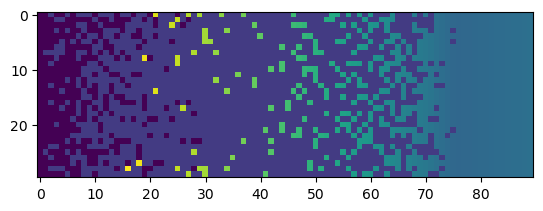

In [508]:
importlib.reload(brack2bing)
icesim = brack2bing.LatticeSolver.load()
lattice = icesim.gen_lattice(*TSR, hshape=(30,30))
llatice = lattice[0,0,1:-1,25,1:-1].cpu(); llatice[llatice < 0] = -30; plt.imshow(llatice); plt.show()

In [464]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML

fig, ax = plt.subplots(figsize=(2,5))
line = np.ones_like(llatice.T); line[0,0] = llatice.min(); line[1,1] = llatice.max(); line = ax.imshow(line)

def animf(t):
    llatice = lattice[0,0,1:-1,t+1,1:-1].cpu(); llatice[llatice < 0] = -10;
    llatice[llatice > 0] += 30
    line.set_data(llatice.T); return line,
ani = FuncAnimation(fig, animf, frames=llatice.shape[-2], interval=750)
plt.close(fig)

ani.save('tmp.gif', writer=PillowWriter(fps=1.5))

#HTML(ani.to_html5_video())

In [509]:
icesim.anneal(lattice, TSR[0,None,None,None,], TSR[1,None,None,None,], (11,11,5), iters=3, verbose=True)
#llatice = lattice[0,0,1:-1,25,1:-1].cpu(); llatice[llatice < 0] = -10; llatice[llatice > 0] = 10
#plt.imshow(llatice); plt.show()
#plt.imshow(lattice[0,0,1:-1,25,1:-1].cpu()); plt.show()

pbf+ step 0 : tensor(0.5865, device='cuda:0') tensor(0.9384, device='cuda:0') tensor(1., device='cuda:0')
pbf- step 0 : tensor(1., device='cuda:0') tensor(1., device='cuda:0') tensor(1., device='cuda:0')
pCS step 0 : tensor(0.6188, device='cuda:0') tensor(0.9152, device='cuda:0') tensor(1., device='cuda:0')
---
pbf+ step 1 : tensor(0.4299, device='cuda:0') tensor(0.8071, device='cuda:0') tensor(1., device='cuda:0')
pbf- step 1 : tensor(1., device='cuda:0') tensor(1., device='cuda:0') tensor(1., device='cuda:0')
pCS step 1 : tensor(0.9783, device='cuda:0') tensor(0.9995, device='cuda:0') tensor(1., device='cuda:0')
---
pbf+ step 2 : tensor(0.1923, device='cuda:0') tensor(0.3418, device='cuda:0') tensor(1., device='cuda:0')
pbf- step 2 : tensor(1., device='cuda:0') tensor(1., device='cuda:0') tensor(1., device='cuda:0')
pCS step 2 : tensor(0.9989, device='cuda:0') tensor(1.0000, device='cuda:0') tensor(1., device='cuda:0')
---


In [510]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML

fig, ax = plt.subplots(figsize=(2,5))
line = np.ones_like(llatice.T); line[0,0] = llatice.min(); line[1,1] = llatice.max(); line = ax.imshow(line)

def animf(t):
    llatice = lattice[0,0,1:-1,t+1,1:-1].cpu(); llatice[llatice < 0] = -10;
    llatice[llatice > 0] += 30
    line.set_data(llatice.T); return line,
ani = FuncAnimation(fig, animf, frames=llatice.shape[-2], interval=750)
plt.close(fig)

#ani.save('tmp.gif', writer=PillowWriter(fps=1.5))

HTML(ani.to_html5_video())




In [50]:
np.array((15,15,3)) % 2

array([1, 1, 1])